#Python DA Assignment 2 - Data Visualization

##1) Loading the Taxis Dataset

Load the Taxis dataset using the Seaborn library

In [198]:
import seaborn as sns
import pandas as pd

df = sns.load_dataset('taxis').head(650)
print("Dataset shape:", df.shape)

Dataset shape: (650, 14)


Seaborn is a Python library used for data visualization. It also provides built-in datasets that we can use for practice and analysis.

Pandas is a Python library used to organize, manipulate, and analyse data. It allows us to work with data in a table format, similar to a spreadsheet in Excel.

The original Taxis dataset contains 6,433 rows. But i selected the first 650 rows to work with a smaller dataset while learning and completing the analysis.

'df.shape' returns the number of rows and columns in the dataset.

##2. Handling Missing Values

➢ Check for missing values in the dataset and identify columns with missing data

➢ Impute missing values using appropriate strategies based on the column type (e.g.,
using mean, median, or mode for numerical columns, and mode for categorical
columns).

➢ For columns that are critical and cannot be reasonably imputed, remove rows with
missing values to maintain data integrity.

In [199]:
print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            5
pickup_zone        3
dropoff_zone       2
pickup_borough     3
dropoff_borough    2
dtype: int64


here , isnull() checks every cell and identifies whether its value is missing and sum() counts the missing values in each column. Here you can see columns - payment, pickup zone drop off zone, pickup borough and drop off borough have missing values

- check the data type of each column to understand how the information is stored.

In [200]:
print(df.dtypes)

pickup             datetime64[ns]
dropoff            datetime64[ns]
passengers                  int64
distance                  float64
fare                      float64
tip                       float64
tolls                     float64
total                     float64
color                      object
payment                    object
pickup_zone                object
dropoff_zone               object
pickup_borough             object
dropoff_borough            object
dtype: object


- Display the rows that contain at least one missing value so that we can examine the affected records before deciding how to handle them.

In [201]:
print(df[df.isnull().any(axis=1)])

                 pickup             dropoff  passengers  distance   fare  \
7   2019-03-22 12:47:13 2019-03-22 12:58:17           0       1.4    8.5   
42  2019-03-30 23:59:14 2019-03-30 23:59:17           1       0.0   80.0   
445 2019-03-19 06:57:14 2019-03-19 07:00:08           1       1.3    5.5   
491 2019-03-07 07:11:33 2019-03-07 07:11:39           1       1.6    2.5   
545 2019-03-27 11:03:43 2019-03-27 11:14:34           1       4.2   15.0   
606 2019-03-19 15:04:40 2019-03-19 15:06:15           1       0.4    3.5   
621 2019-03-15 17:16:35 2019-03-15 17:25:01           1       1.3    7.5   
622 2019-03-12 19:52:36 2019-03-12 19:52:55           3       0.0  120.0   

       tip  tolls   total   color      payment            pickup_zone  \
7     0.00    0.0   11.80  yellow          NaN            Murray Hill   
42   20.08    0.0  100.38  yellow  credit card                    NaN   
445   0.00    0.0    6.30  yellow          NaN            Boerum Hill   
491   0.00    0.0    5.

Here , df.isnull() checks which values are missing.
.any(axis=1) checks each row to see whether at least one value is missing.

- Identify the Most Frequently Occurring Values

In [202]:
print(df['payment'].mode())
print(df['pickup_zone'].mode())
print(df['dropoff_zone'].mode())
print(df['pickup_borough'].mode())
print(df['dropoff_borough'].mode())

0    credit card
Name: payment, dtype: object
0    Midtown Center
Name: pickup_zone, dtype: object
0    Midtown Center
Name: dropoff_zone, dtype: object
0    Manhattan
Name: pickup_borough, dtype: object
0    Manhattan
Name: dropoff_borough, dtype: object


Here we used mode because the mode is the value that appears most frequently in a column. I needed to identify the most frequently occurring values before deciding how to replace missing categorical information.

----------------------------------------------------------------------------

###Remove rows with missing values

In [203]:
df = df.drop(index=42)

Here, i chose to remove row 42 because its pickup zone, dropoff zone, pickup borough, and dropoff borough values were all missing. Keeping this row with unknown location information could affect the location based analysis.

In [204]:
print(df.shape)

(649, 14)


In [205]:
df = df.drop(index=622)

here, i  chose to remove 622th row because its dropoff zone, pickup borough, and dropoff borough values were missing,s, making the record less suitable for location-based analysis.

-----------------------------------------------------------------------------------------------------

###Impute missing values

- Replace missing values in the payment column with the mode, which is the most frequently occurring payment method.

In [206]:
df['payment'] = df['payment'].fillna(df['payment'].mode()[0])

The mode was credit card, so the missing payment values were replaced with credit card. Here , ".mode()" finds the most frequently occurring payment method. "[0]" selects the first mode value. ".fillna()" replaces missing values with the selected value.

In [207]:
print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        1
dropoff_zone       0
pickup_borough     1
dropoff_borough    0
dtype: int64


In [208]:
print(df[df.isnull().any(axis=1)])

                 pickup             dropoff  passengers  distance  fare   tip  \
606 2019-03-19 15:04:40 2019-03-19 15:06:15           1       0.4   3.5  1.35   

     tolls  total   color      payment pickup_zone           dropoff_zone  \
606    0.0   8.15  yellow  credit card         NaN  Upper East Side South   

    pickup_borough dropoff_borough  
606            NaN       Manhattan  


- Replace the missing value in the pickup_zone column with the most frequently occurring pickup zone.

In [209]:
df['pickup_zone'] = df['pickup_zone'].fillna(df['pickup_zone'].mode()[0])

The mode was Midtown center, so the missing payment values were replaced with Midtwon center. here , ".mode()[0]" selects the most frequently occurring pickup zone. ".fillna()" replaces any missing pickup zone with that value(Midtwon center)

- Replace the missing value in the pickup_borough column with the most frequently occurring pickup borough.

In [210]:
df['pickup_borough'] = df['pickup_borough'].fillna(df['pickup_borough'].mode()[0])

The mode was Manhattan, so the missing payment values were replaced with Manhattan.

In [211]:
print(df.isnull().sum())

pickup             0
dropoff            0
passengers         0
distance           0
fare               0
tip                0
tolls              0
total              0
color              0
payment            0
pickup_zone        0
dropoff_zone       0
pickup_borough     0
dropoff_borough    0
dtype: int64


We use isnull() to identify missing values and sum() to count them in each column.here my  latest output showed zero missing values in all columns.
This confirms that the dataset no longer contains missing values after our cleaning steps.

--------------------------------------------------------------------------------------------------

##3) Visualizations using Matplotlib/Pandas Plot

★ Line Chart

Plot a line chart to visualize the fare over time, using the pickup timestamp as the
x-axis and fare as the y-axis. Ensure the pickup column is converted to a datetime
format before plotting.

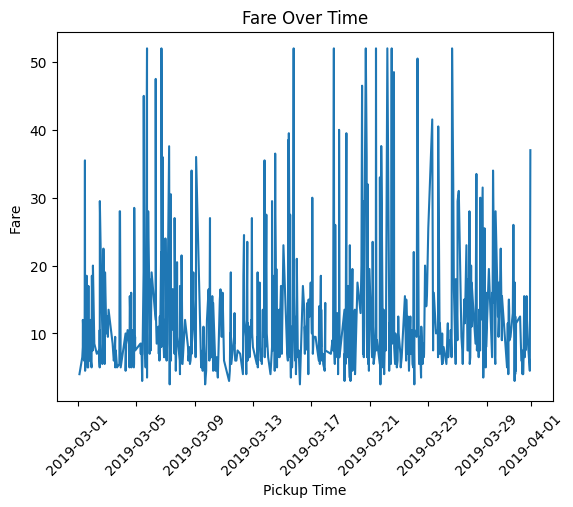

In [212]:
import matplotlib.pyplot as plt

df['pickup'] = pd.to_datetime(df['pickup'])
df = df.sort_values('pickup')

plt.plot(df['pickup'], df['fare'])
plt.title('Fare Over Time')
plt.xlabel('Pickup Time')
plt.ylabel('Fare ')
plt.xticks(rotation=45)
plt.show()

import matplotlib.pyplot as plt imports the Matplotlib library, which is used to create visualizations in Python.

First, the pickup column was converted into datetime format using pd.to_datetime(), and the data was sorted by pickup time using sort_values(). A line chart was created using plt.plot() to visualize how taxi fares change over time, with pickup time on the x-axis and fare on the y-axis. A title and labels were added to make the chart easy to understand. Initially, the date labels on the x-axis overlapped, making them difficult to read. To fix this, I searched for a solution and used plt.xticks(rotation=45), which rotates the date labels by 45 degrees and improves readability. Finally, plt.show() was used to display the chart.

★ Bar Chart

Create a bar chart to show the total fare for each pickup_borough. Group the data
by pickup_borough and sum the fare for each group.

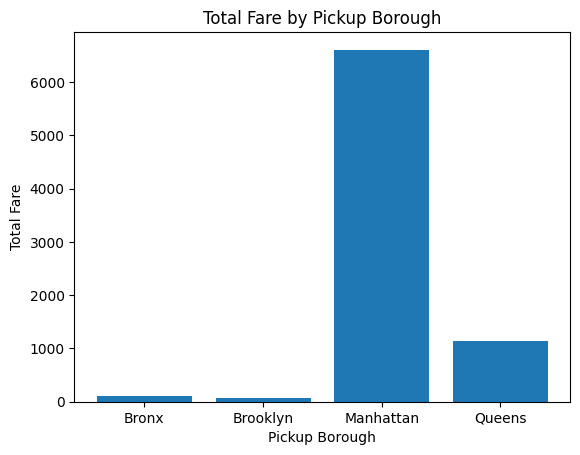

In [213]:
total_fare = df.groupby('pickup_borough')['fare'].sum()
plt.bar(total_fare.index, total_fare.values)
plt.title('Total Fare by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Total Fare')
plt.show()

df.groupby('pickup_borough') - Groups the trips according to their pickup borough.  ['fare'].sum() - Adds the fares of all trips within each borough. Stores the calculated total fares in a variable named total_fare.  'plt.bar(total_fare.index, total_fare.values)' - Creates the bar chart. The borough names appear on the x-axis, and their total fares appear on the y-axis. total_fare.index gives the borough names .  plt.title() - Adds a title to the chart.  plt.xlabel() and plt.ylabel() - Label the x-axis and y-axis.

★ Pie Chart

Plot a pie chart showing the distribution of trips based on the payment method (credit
card, cash, etc.). Each slice should represent the count of trips for a specific payment
method.

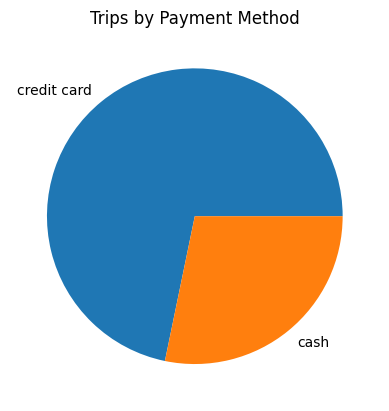

In [214]:
payment_counts = df['payment'].value_counts()
plt.pie(payment_counts.values, labels=payment_counts.index)
plt.title('Trips by Payment Method')
plt.show()

First, I used value_counts() to count the number of trips for each payment method and stored the results in payment_counts. Then, I used plt.pie() to create a pie chart, where each slice represents the number of trips paid for using credit card or cash.  payment_counts.values gives the actual counts (numbers) of trips for each payment method. payment_counts.index gives us the payment method names meand here Credit card and cash. then i used plt.title() to add a title and plt.show() to display the chart

★ Histogram

Create a histogram to visualize the distribution of distance. Customize the number of
bins for better granularity and ensure the plot is easy to interpret.

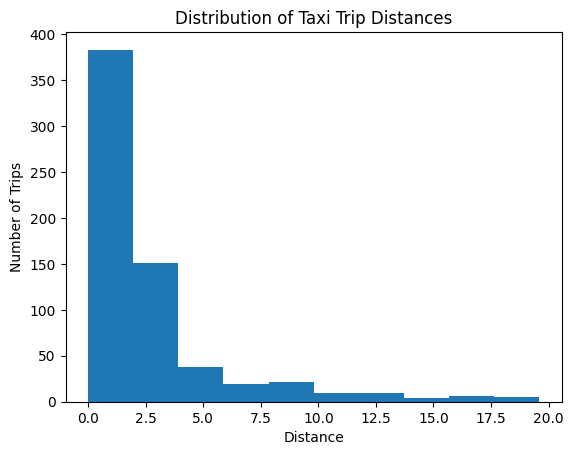

In [215]:
plt.hist(df['distance'], bins=10)
plt.title('Distribution of Taxi Trip Distances')
plt.xlabel('Distance')
plt.ylabel('Number of Trips')
plt.show()

First, I used plt.hist() to create a histogram showing the distribution of taxi trip distances .df['distance']  Selects the distance column from the dataset.  I set bins=10 to divide the distance values into 10 intervals. I added a title using plt.title() and labelled the x-axis as Trip Distance and the y-axis as Number of Trips using plt.xlabel() and plt.ylabel() respectivel. The chart shows that most trips have shorter distances, while only a few trips have longer distances.

★ Box Plot

Plot a box plot to visualize the distribution of tip amounts for each pickup_borough.
Use pickup_borough as the categorical axis and tip as the numeric axis.

In [220]:
df['pickup_borough'].unique()

array(['Manhattan', 'Queens', 'Bronx', 'Brooklyn'], dtype=object)

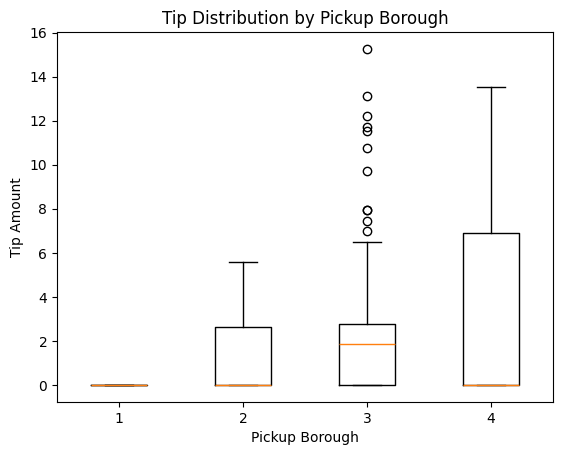

In [226]:
bronx = df[df['pickup_borough'] == 'Bronx']['tip']
brooklyn = df[df['pickup_borough'] == 'Brooklyn']['tip']
manhattan = df[df['pickup_borough'] == 'Manhattan']['tip']
queens = df[df['pickup_borough'] == 'Queens']['tip']

plt.boxplot([bronx, brooklyn, manhattan, queens])
plt.title('Tip Distribution by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Tip Amount')
plt.show()

 I separated the tip amounts according to the four pickup boroughs - Bronx, Brooklyn, Manhattan, and Queens.The first four lines separate the tip amounts for each borough (bronx = df[df['pickup_borough'] == 'Bronx']['tip'])  .  I used plt.boxplot() to create a box plot for each borough,  displaying four box plots, it was easy compare the distribution of tip amounts across the different boroughs. Used filtering to select the rows belonging to each borough and then selected the tip column to obtain the tip amounts for that borough.

---------------------------------------------------------------------------------------------------------------

##Visualizations using Seaborn

★ Count Plot

Create a count plot to visualize the number of trips in each pickup_borough. The
x-axis should represent the boroughs, and the y-axis should show the count of trips.

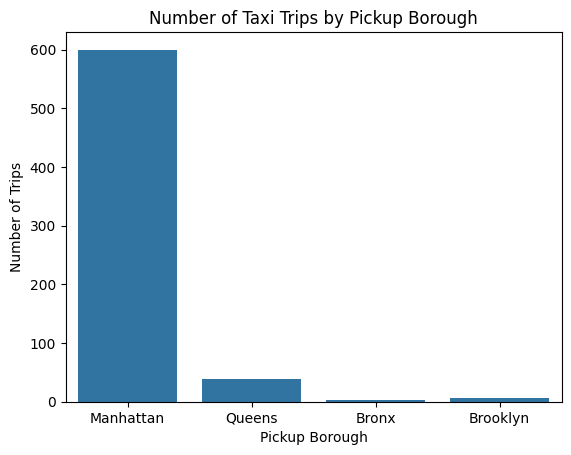

In [228]:
sns.countplot(x='pickup_borough', data=df)
plt.title('Number of Taxi Trips by Pickup Borough')
plt.xlabel('Pickup Borough')
plt.ylabel('Number of Trips')
plt.show()

Here, I used `sns.countplot()` to visualize the number of taxi trips for each pickup borough. The function automatically counts the number of trips belonging to each borough and displays the counts on the y-axis. I used `plt.title()` to add a title and `plt.xlabel()` and `plt.ylabel()` to label the x-axis and y-axis.

★ Scatter Plot

Plot a scatter plot to show the relationship between distance and fare. Use
distance on the x-axis and fare on the y-axis to visualize any correlation. Color the
points based on the pickup_borough to differentiate the trips by their respective
boroughs.

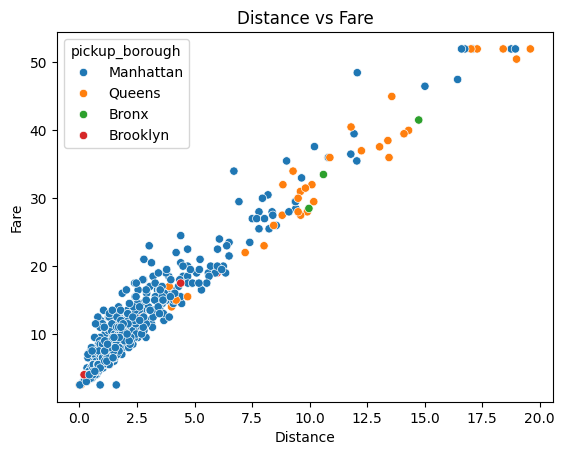

In [233]:
sns.scatterplot(x='distance', y='fare', hue='pickup_borough' , data=df)
plt.title('Distance vs Fare')
plt.xlabel('Distance')
plt.ylabel('Fare')
plt.show()

First, I used sns.scatterplot() to create a scatter plot showing the relationship between trip distance and fare. I used distance on the x-axis and fare on the y-axis. The scatter plot helps us understand how taxi fares change with trip distance. It can show whether longer trips generally have higher fares. hue='pickup_borough' is  used for different colors for the boroughs, making it easier to distinguish them on the scatter plot.

★ Heatmap

Plot a heatmap to visualize the correlation between numerical variables such as
distance, fare, tip, tolls, and total. Use a correlation matrix to highlight the
relationships.

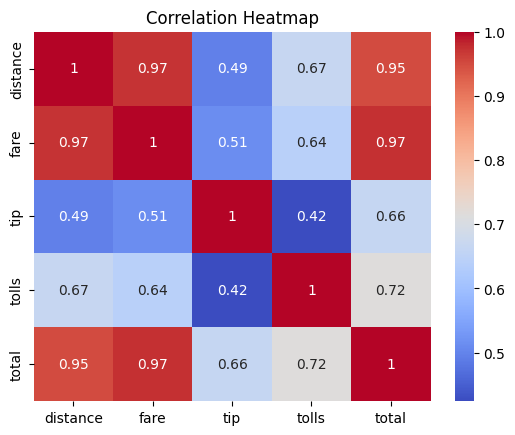

In [234]:
correlation = df[['distance', 'fare', 'tip', 'tolls', 'total']].corr()
sns.heatmap(correlation, annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()

First, I selected the numerical variables distance, fare, tip, tolls, and total from the dataset. I used .corr() to calculate the correlation matrix, which shows the relationships between these variables.

Next, I used sns.heatmap() to visualize the correlation matrix. The parameter annot=True displays the correlation values inside the cells, and cmap='coolwarm' sets the colour scheme of the heatmap.

★ Pair Plot

Create a pair plot to visualize the pairwise relationships between distance, fare, tip,
and total. Color the data points according to the pickup_zone method to compare
how different zones affect these variables.

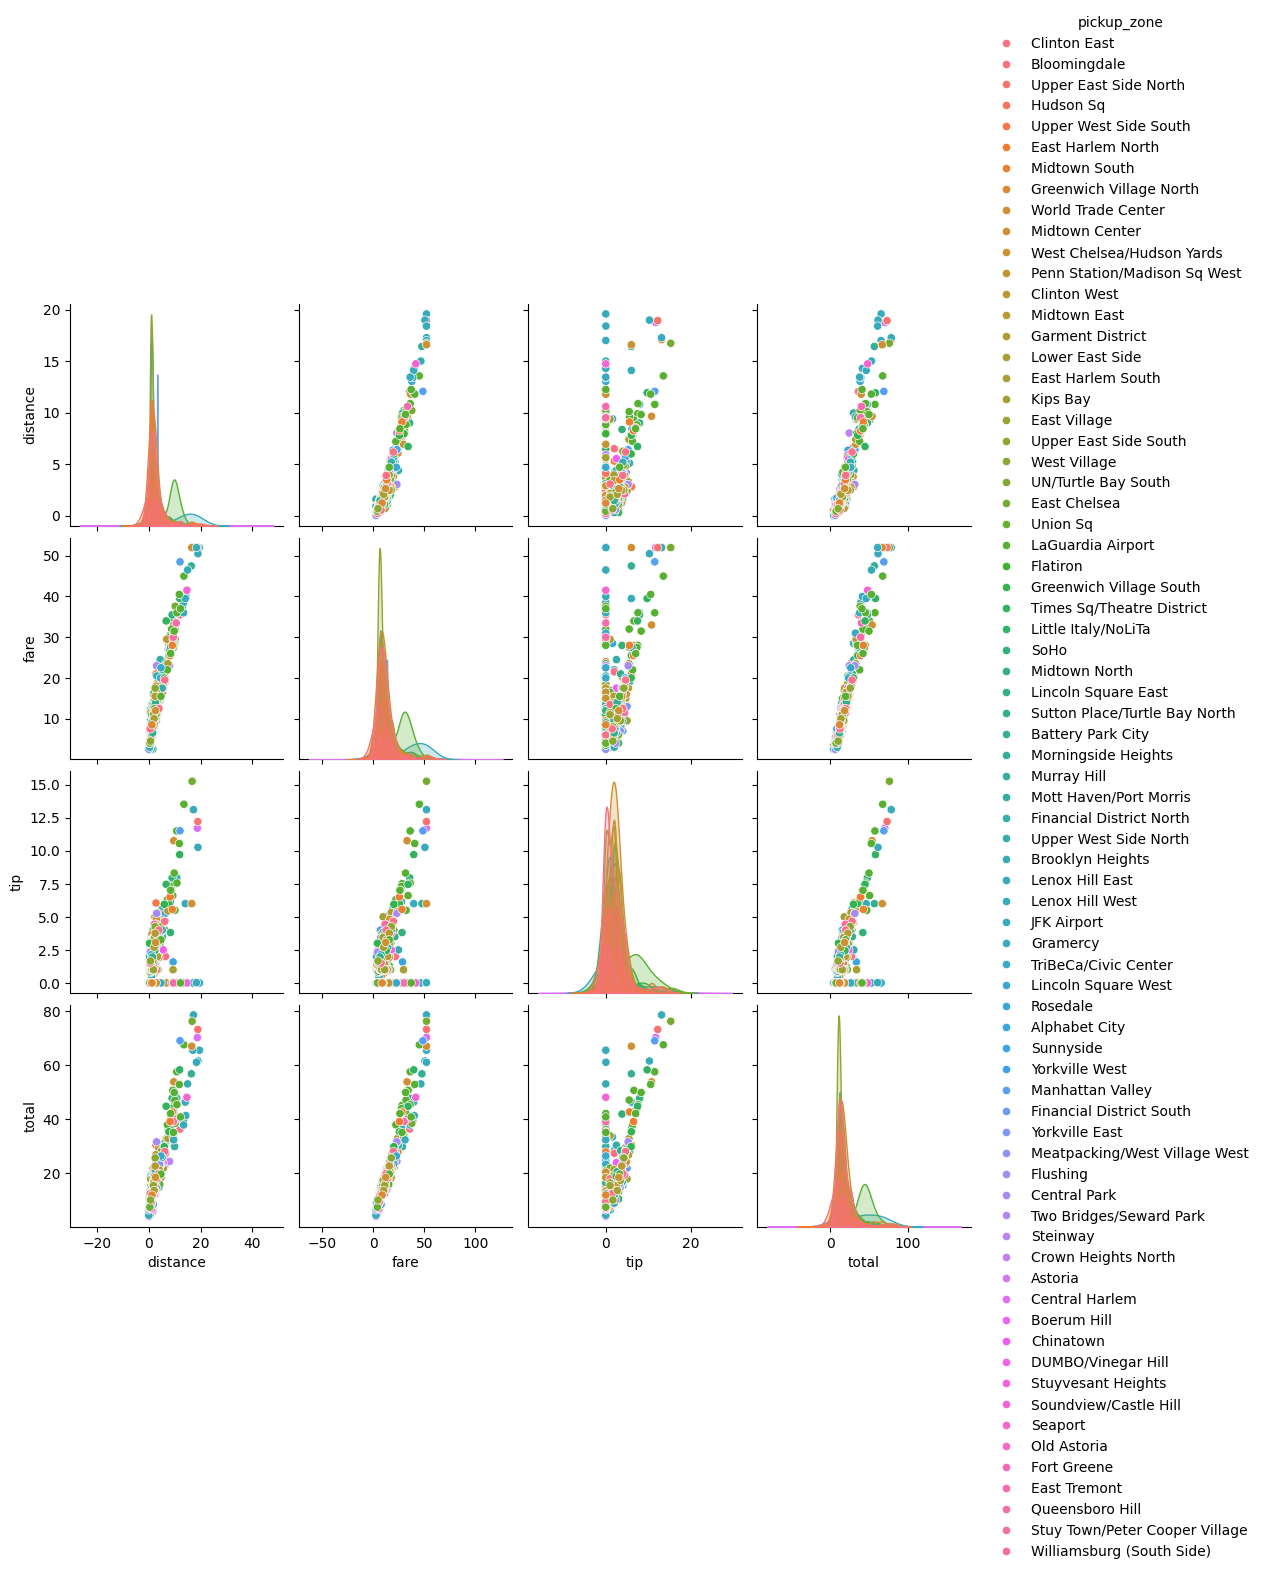

In [236]:
sns.pairplot(df[['distance', 'fare', 'tip', 'total', 'pickup_zone']], hue='pickup_zone')
plt.show()

First, I selected the numerical variables distance, fare, tip, and total, along with the pickup_zone, from the dataset.
Next, I used sns.pairplot() to visualize the pairwise relationships between the numerical variables. I used hue='pickup_zone' to display data points in different colours according to their pickup zones. This helps compare the relationships between the variables across different zones

★ Violin Plot

Plot a violin plot to show the distribution of fare for each payment method. Use the
payment method as the categorical axis and fare as the numeric axis to visualize its
distribution.

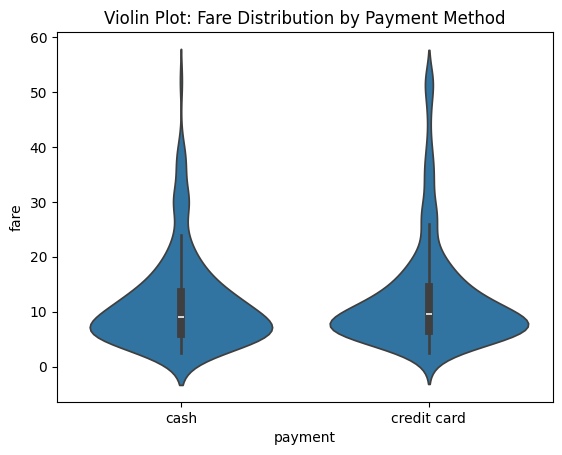

In [237]:
sns.violinplot(data=df, x='payment', y='fare')
plt.title('Violin Plot: Fare Distribution by Payment Method')
plt.show()

First, I used sns.violinplot() to create a violin plot showing the distribution of taxi fares for each payment method. I used payment as the categorical axis and fare as the numerical axis. The violin plot shows the distribution and shape of the fare data for each payment method.